# Sales Category Prediction Using Deep Learning (ANN, RNN, LSTM)

## 1. Installation and Imports

In [ ]:
!pip -q install kagglehub

import os
import glob
import time
import copy
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import kagglehub

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", device)

Using Device: cpu


## 2. Dataset Download

In [ ]:
print("Downloading Dataset...")
path = kagglehub.dataset_download("rohitsahoo/sales-forecasting")
csv_files = glob.glob(path + "/**/*.csv", recursive=True)

if not csv_files:
    raise FileNotFoundError("CSV file not found!")

file_path = next(
    (f for f in csv_files if os.path.basename(f).lower() == "train.csv"),
    csv_files[0]
)

df = pd.read_csv(file_path)
print("Dataset Downloaded Successfully!")
print("Shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'sales-forecasting' dataset.
Dataset Downloaded Successfully!
Shape: (9800, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


## 3. Data Cleaning

In [ ]:
df.columns = df.columns.str.strip()
df.drop_duplicates(inplace=True)

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df.dropna(subset=["Sales"], inplace=True)
df = df[df["Sales"] >= 0].copy()

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df.dropna(subset=["Order Date"], inplace=True)

df.sort_values("Order Date", inplace=True)
df.reset_index(drop=True, inplace=True)

print("Cleaned Dataset Preview:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Cleaned Dataset Preview:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,541,CA-2015-140795,2015-01-02,03/02/2015,First Class,BD-11500,Bradley Drucker,Consumer,United States,Green Bay,Wisconsin,54302.0,Central,TEC-AC-10001432,Technology,Accessories,Enermax Aurora Lite Keyboard,468.900
1,6548,CA-2015-113880,2015-01-03,05/03/2015,Standard Class,VF-21715,Vicky Freymann,Home Office,United States,Elmhurst,Illinois,60126.0,Central,FUR-CH-10000863,Furniture,Chairs,Novimex Swivel Fabric Task Chair,634.116
2,158,CA-2015-104269,2015-01-03,06/03/2015,Second Class,DB-13060,Dave Brooks,Consumer,United States,Seattle,Washington,98115.0,West,FUR-CH-10004063,Furniture,Chairs,Global Deluxe High-Back Manager's Chair,457.568
3,7948,CA-2015-131009,2015-01-03,05/03/2015,Standard Class,SC-20380,Shahid Collister,Consumer,United States,El Paso,Texas,79907.0,Central,OFF-FA-10004395,Office Supplies,Fasteners,Plymouth Boxed Rubber Bands by Plymouth,18.840
4,7949,CA-2015-131009,2015-01-03,05/03/2015,Standard Class,SC-20380,Shahid Collister,Consumer,United States,El Paso,Texas,79907.0,Central,FUR-CH-10001270,Furniture,Chairs,Harbour Creations Steel Folding Chair,362.250



Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      4
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64


## 4. Sales Categorization

In [ ]:
def sales_category(sales):
    if sales < 100:
        return 0
    elif sales < 500:
        return 1
    else:
        return 2

df["Sales_Category"] = df["Sales"].apply(sales_category)

category_names = {
    0: "Low",
    1: "Medium",
    2: "High"
}

df["Category_Name"] = df["Sales_Category"].map(category_names)
print("Sales Category Distribution:")
print(df["Category_Name"].value_counts())

Sales Category Distribution:
Category_Name
Low       2474
Medium    1042
High       443
Name: count, dtype: int64


## 5. Exploratory Data Analysis

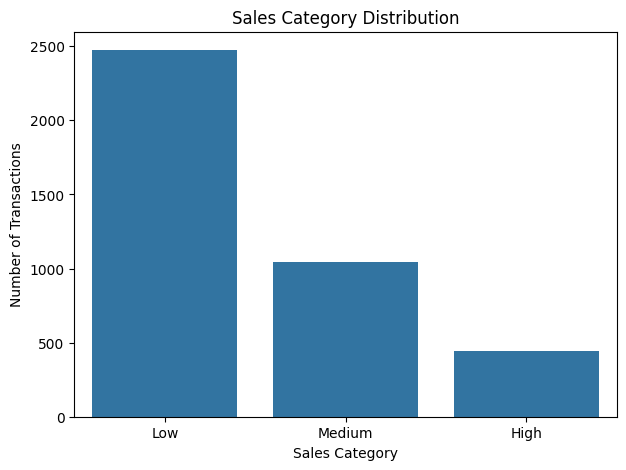

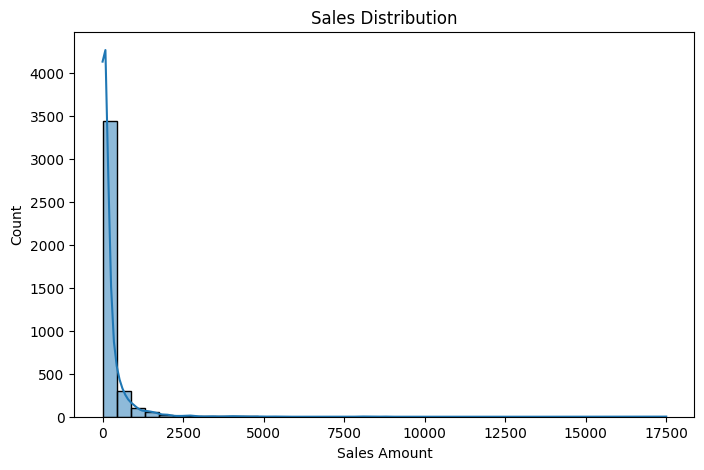

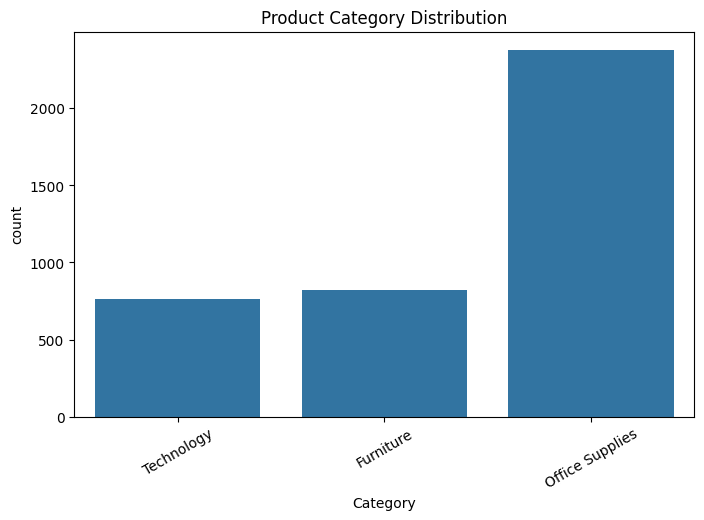

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Category_Name", order=["Low", "Medium", "High"])
plt.title("Sales Category Distribution")
plt.xlabel("Sales Category")
plt.ylabel("Number of Transactions")
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df["Sales"], bins=40, kde=True)
plt.title("Sales Distribution")
plt.xlabel("Sales Amount")
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Category")
plt.title("Product Category Distribution")
plt.xticks(rotation=30)
plt.show()

## 6. Feature Selection

In [ ]:
numeric_columns = [col for col in ["Sales", "Quantity", "Discount"] if col in df.columns]
categorical_columns = [col for col in ["Category", "Sub-Category", "Region", "Segment", "Ship Mode"] if col in df.columns]

features = df[numeric_columns].copy()

for col in categorical_columns:
    encoded = pd.get_dummies(
        df[col].fillna("Unknown"),
        prefix=col,
        dtype=float
    )
    features = pd.concat([features, encoded], axis=1)

features = features.replace([np.inf, -np.inf], np.nan)
features = features.fillna(0)

print("Selected Features:")
print(features.columns.tolist())

Selected Features:
['Sales', 'Category_Furniture', 'Category_Office Supplies', 'Category_Technology', 'Sub-Category_Accessories', 'Sub-Category_Appliances', 'Sub-Category_Art', 'Sub-Category_Binders', 'Sub-Category_Bookcases', 'Sub-Category_Chairs', 'Sub-Category_Copiers', 'Sub-Category_Envelopes', 'Sub-Category_Fasteners', 'Sub-Category_Furnishings', 'Sub-Category_Labels', 'Sub-Category_Machines', 'Sub-Category_Paper', 'Sub-Category_Phones', 'Sub-Category_Storage', 'Sub-Category_Supplies', 'Sub-Category_Tables', 'Region_Central', 'Region_East', 'Region_South', 'Region_West', 'Segment_Consumer', 'Segment_Corporate', 'Segment_Home Office', 'Ship Mode_First Class', 'Ship Mode_Same Day', 'Ship Mode_Second Class', 'Ship Mode_Standard Class']


## 7. Sequential Data Preparation

In [ ]:
SEQ_LENGTH = 10
X_raw = features.values.astype(np.float32)
y_raw = df["Sales_Category"].values.astype(np.int64)

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

if n <= SEQ_LENGTH + 20:
    raise ValueError("Insufficient dataset records!")

scaler = StandardScaler()
scaler.fit(X_raw[:train_end])
X_scaled = scaler.transform(X_raw).astype(np.float32)

X_sequences = []
y_sequences = []
target_indices = []

for i in range(SEQ_LENGTH, n):
    X_sequences.append(X_scaled[i-SEQ_LENGTH:i])
    y_sequences.append(y_raw[i])
    target_indices.append(i)

X_sequences = np.array(X_sequences, dtype=np.float32)
y_sequences = np.array(y_sequences, dtype=np.int64)
target_indices = np.array(target_indices)

train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end

X_train, y_train = X_sequences[train_mask], y_sequences[train_mask]
X_val, y_val = X_sequences[val_mask], y_sequences[val_mask]
X_test, y_test = X_sequences[test_mask], y_sequences[test_mask]

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (2761, 10, 32)
Validation Shape: (594, 10, 32)
Testing Shape: (594, 10, 32)


## 8. PyTorch DataLoaders & Class Weights

In [ ]:
def create_loader(X, y, shuffle=False):
    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    dataset = TensorDataset(X_tensor, y_tensor)
    return DataLoader(dataset, batch_size=64, shuffle=shuffle)

train_loader = create_loader(X_train, y_train, shuffle=True)
val_loader = create_loader(X_val, y_val)
test_loader = create_loader(X_test, y_test)

class_counts = np.bincount(y_train, minlength=3)
class_weights = len(y_train) / (3 * np.maximum(class_counts, 1))
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("Class weights:", class_weights)

Class weights: tensor([0.5366, 1.2818, 2.8059])


## 9. Model Architecture Definitions (ANN, RNN, LSTM)

In [ ]:
class ANN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_size * SEQ_LENGTH, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 3)
        )
    def forward(self, x):
        return self.network(x)

class RNNModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )
        self.fc = nn.Linear(64, 3)
    def forward(self, x):
        output, hidden = self.rnn(x)
        return self.fc(output[:, -1, :])

class LSTMModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )
        self.fc = nn.Linear(64, 3)
    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)
        return self.fc(output[:, -1, :])

## 10. Model Training Setup

In [ ]:
EPOCHS = 100
PATIENCE = 10
LEARNING_RATE = 0.001

def train_model(model, name):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {
        "train_loss": [], "val_loss": [],
        "train_accuracy": [], "val_accuracy": []
    }
    best_loss = float("inf")
    best_weights = None
    patience_count = 0
    start_time = time.time()

    print(f"\nTraining: {name}")
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0
        actual, predicted = [], []

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(yb)
            predictions = outputs.argmax(dim=1)
            actual.extend(yb.cpu().numpy())
            predicted.extend(predictions.detach().cpu().numpy())

        train_loss = total_loss / len(train_loader.dataset)
        train_accuracy = accuracy_score(actual, predicted)

        model.eval()
        val_loss_total = 0
        val_actual, val_predicted = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                outputs = model(xb)
                loss = criterion(outputs, yb)
                val_loss_total += loss.item() * len(yb)
                predictions = outputs.argmax(dim=1)
                val_actual.extend(yb.cpu().numpy())
                val_predicted.extend(predictions.cpu().numpy())

        val_loss = val_loss_total / len(val_loader.dataset)
        val_accuracy = accuracy_score(val_actual, val_predicted)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Train Acc: {train_accuracy:.4f} | Val Acc: {val_accuracy:.4f}")

        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            patience_count = 0
        else:
            patience_count += 1

        if patience_count >= PATIENCE:
            print("Early Stopping Triggered!")
            break

    model.load_state_dict(best_weights)
    training_time = time.time() - start_time
    print(f"{name} Training Completed in {round(training_time, 2)} seconds")
    return model, history, training_time

## 11. Train All Three Models

In [ ]:
input_size = X_train.shape[2]
models = {
    "ANN": ANN(input_size),
    "RNN": RNNModel(input_size),
    "LSTM": LSTMModel(input_size)
}

trained_models = {}
histories = {}
training_times = {}

for name, model in models.items():
    trained, history, duration = train_model(model, name)
    trained_models[name] = trained
    histories[name] = history
    training_times[name] = duration


Training: ANN
Epoch 10/100 | Train Loss: 0.4080 | Val Loss: 1.7988 | Train Acc: 0.7823 | Val Acc: 0.4327
Early Stopping Triggered!
ANN Training Completed in 3.25 seconds

Training: RNN
Epoch 10/100 | Train Loss: 0.9852 | Val Loss: 1.1664 | Train Acc: 0.4310 | Val Acc: 0.3620
Early Stopping Triggered!
RNN Training Completed in 9.87 seconds

Training: LSTM
Epoch 10/100 | Train Loss: 0.9373 | Val Loss: 1.2474 | Train Acc: 0.4397 | Val Acc: 0.2963
Early Stopping Triggered!
LSTM Training Completed in 17.19 seconds


## 12. Evaluation & Performance Comparison

In [ ]:
def get_predictions(model, loader):
    model.eval()
    actual, predicted = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            outputs = model(xb)
            predictions = outputs.argmax(dim=1)
            actual.extend(yb.numpy())
            predicted.extend(predictions.cpu().numpy())
    return np.array(actual), np.array(predicted)

results = {}
for name, model in trained_models.items():
    actual, predicted = get_predictions(model, test_loader)
    results[name] = {"actual": actual, "predicted": predicted}

performance = []
for name in results:
    act, pred = results[name]["actual"], results[name]["predicted"]
    performance.append({
        "Model": name,
        "Accuracy": accuracy_score(act, pred),
        "Precision": precision_score(act, pred, average="weighted", zero_division=0),
        "Recall": recall_score(act, pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(act, pred, average="weighted", zero_division=0),
        "Training Time": training_times[name]
    })

performance_df = pd.DataFrame(performance)
display(performance_df)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time
0,ANN,0.289562,0.482717,0.289562,0.307136,3.245554
1,RNN,0.299663,0.473936,0.299663,0.336846,9.873776
2,LSTM,0.358586,0.461530,0.358586,0.369518,17.190555


## 13. Visualizing Results

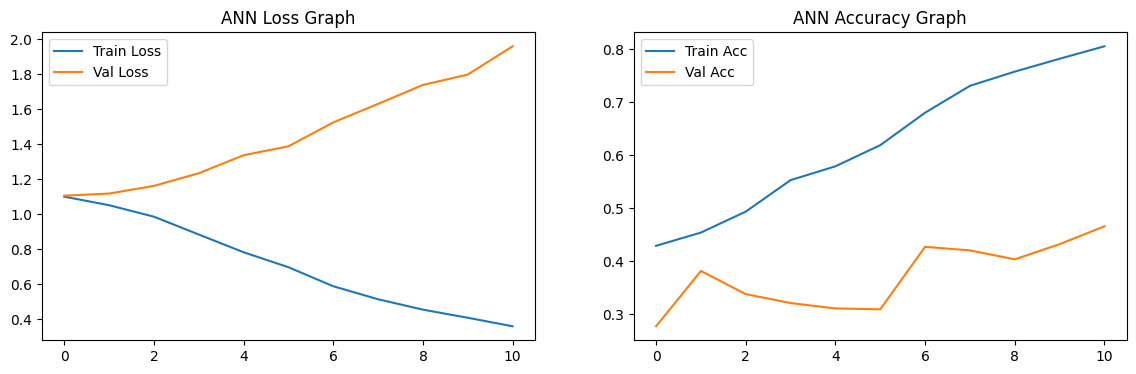

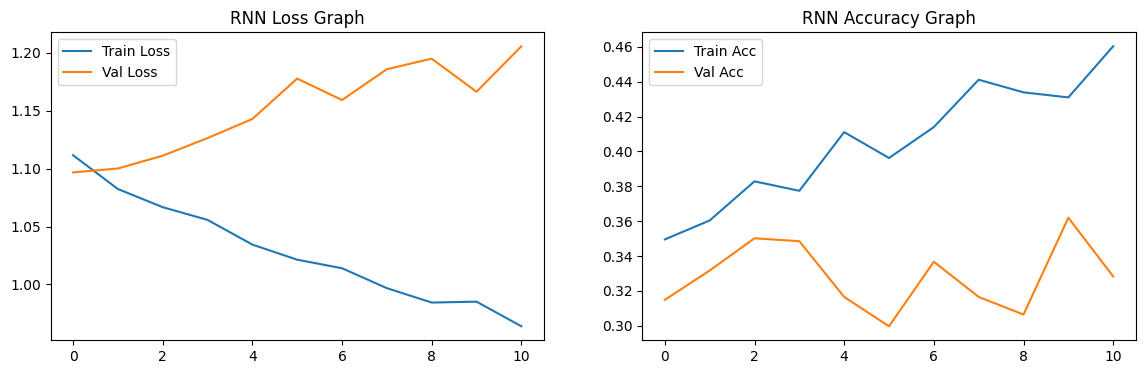

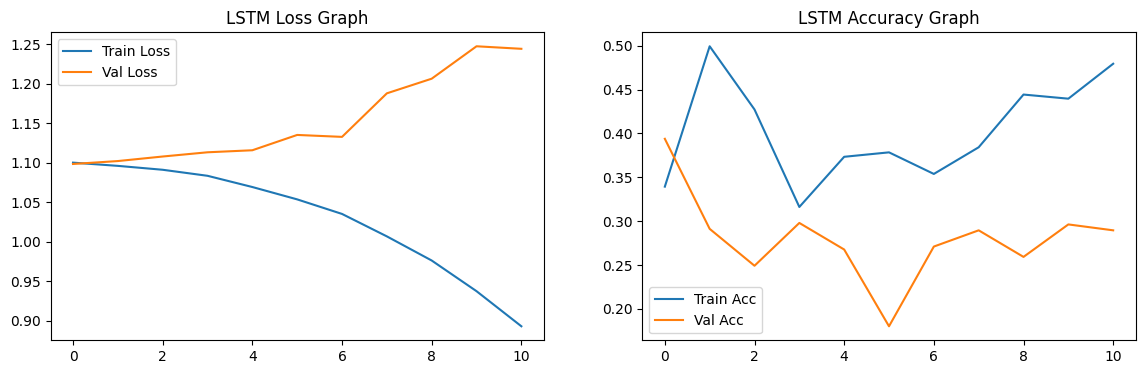

In [ ]:
# Training/Validation curves
for name in histories:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(histories[name]["train_loss"], label="Train Loss")
    axes[0].plot(histories[name]["val_loss"], label="Val Loss")
    axes[0].set_title(f"{name} Loss Graph")
    axes[0].legend()

    axes[1].plot(histories[name]["train_accuracy"], label="Train Acc")
    axes[1].plot(histories[name]["val_accuracy"], label="Val Acc")
    axes[1].set_title(f"{name} Accuracy Graph")
    axes[1].legend()
    plt.show()

## 14. Save Models and Outputs

In [ ]:
os.makedirs("Sales_Category_Results", exist_ok=True)

for name, model in trained_models.items():
    torch.save(model.state_dict(), f"Sales_Category_Results/{name}_model.pth")

joblib.dump(scaler, "Sales_Category_Results/scaler.pkl")
joblib.dump(list(features.columns), "Sales_Category_Results/feature_columns.pkl")

best_row = performance_df.loc[performance_df["F1 Score"].idxmax()]
joblib.dump(best_row["Model"], "Sales_Category_Results/best_model.pkl")

print("Saved all models and artifacts in 'Sales_Category_Results/'")

Saved all models and artifacts in 'Sales_Category_Results/'


Using Device: cpu

Using Colab cache for faster access to the 'sales-forecasting' dataset.
Dataset Downloaded Successfully!
Shape: (9800, 18)
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
1       2  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
2       3  CA-2017-138688  12/06/2017  16/06/2017    Second Class    DV-13045   
3       4  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   
4       5  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City       State  \
0      Claire Gute   Consumer  United States        Henderson    Kentucky   
1      Claire Gute   Consumer  United States        Henderson    Kentucky   
2  Darrin Van Huff  Corporate  United States      Los Angeles  California   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  

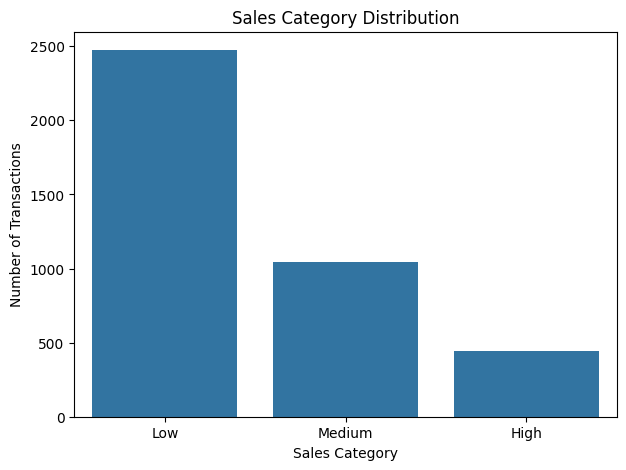

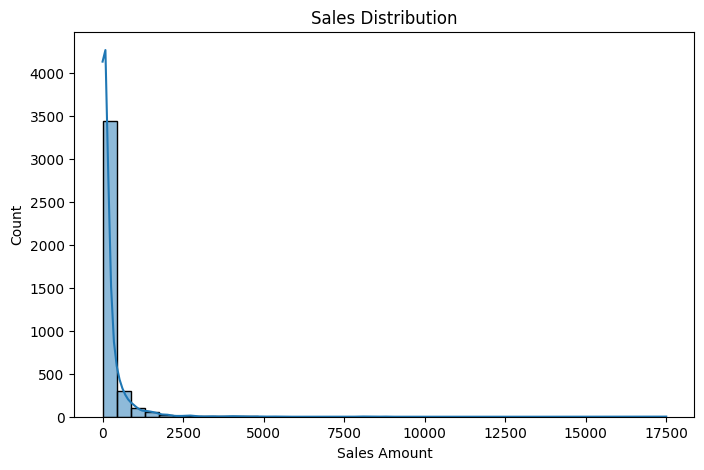

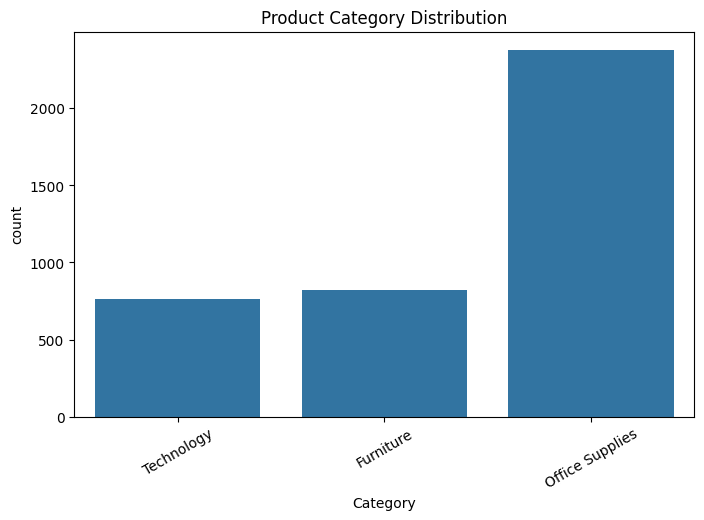


Selected Features:
['Sales', 'Category_Furniture', 'Category_Office Supplies', 'Category_Technology', 'Sub-Category_Accessories', 'Sub-Category_Appliances', 'Sub-Category_Art', 'Sub-Category_Binders', 'Sub-Category_Bookcases', 'Sub-Category_Chairs', 'Sub-Category_Copiers', 'Sub-Category_Envelopes', 'Sub-Category_Fasteners', 'Sub-Category_Furnishings', 'Sub-Category_Labels', 'Sub-Category_Machines', 'Sub-Category_Paper', 'Sub-Category_Phones', 'Sub-Category_Storage', 'Sub-Category_Supplies', 'Sub-Category_Tables', 'Region_Central', 'Region_East', 'Region_South', 'Region_West', 'Segment_Consumer', 'Segment_Corporate', 'Segment_Home Office', 'Ship Mode_First Class', 'Ship Mode_Same Day', 'Ship Mode_Second Class', 'Ship Mode_Standard Class']

Dataset Splitting:
Training: (2761, 10, 32)
Validation: (594, 10, 32)
Testing: (594, 10, 32)

Training: ANN
Epoch 10/100 Train Loss: 0.4080 Val Loss: 1.7988 Train Accuracy: 0.7823 Val Accuracy: 0.4327
Early Stopping Triggered!
ANN Training Completed:

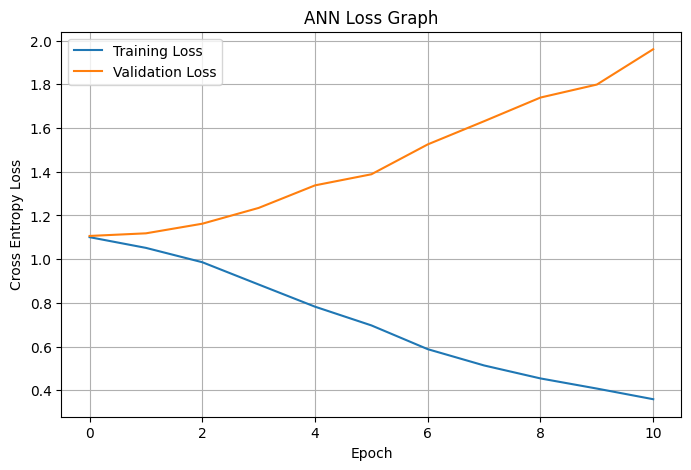

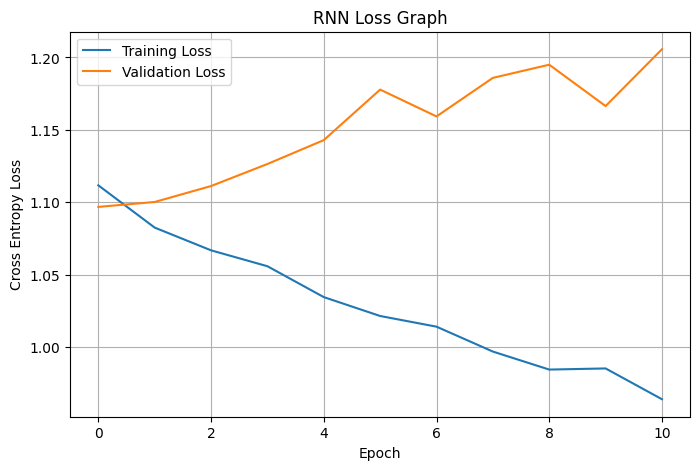

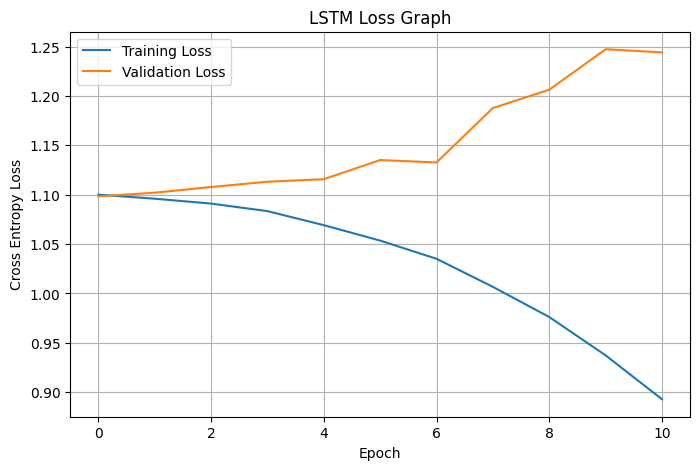

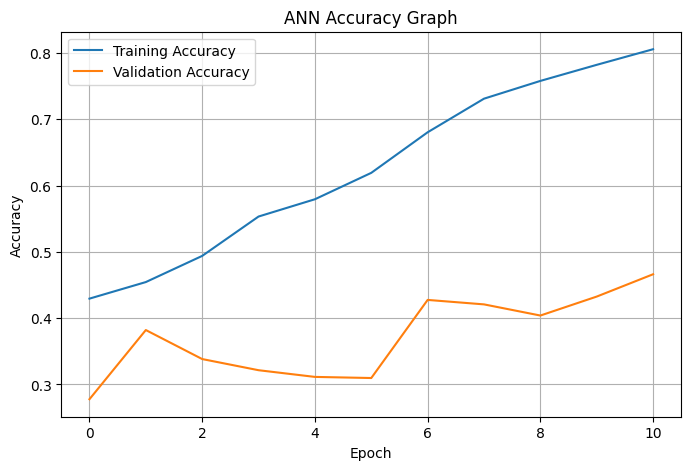

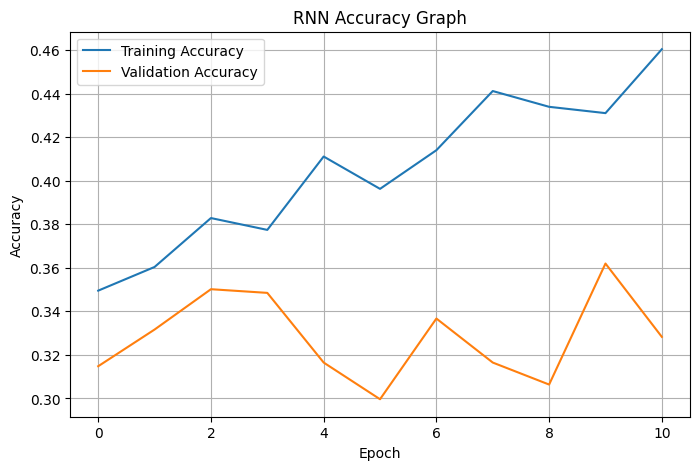

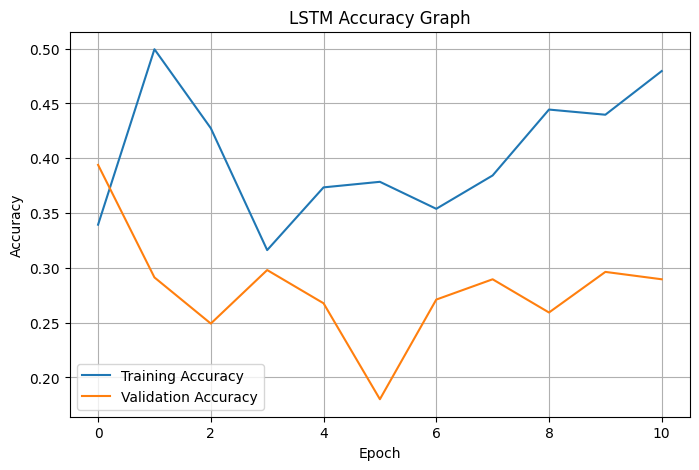


========== CLASSIFICATION RESULTS ==========
Model  Accuracy  Precision  Recall  F1 Score  Training Time
  ANN    0.2896     0.4827  0.2896    0.3071         2.6861
  RNN    0.2997     0.4739  0.2997    0.3368         3.2449
 LSTM    0.3586     0.4615  0.3586    0.3695         7.6114


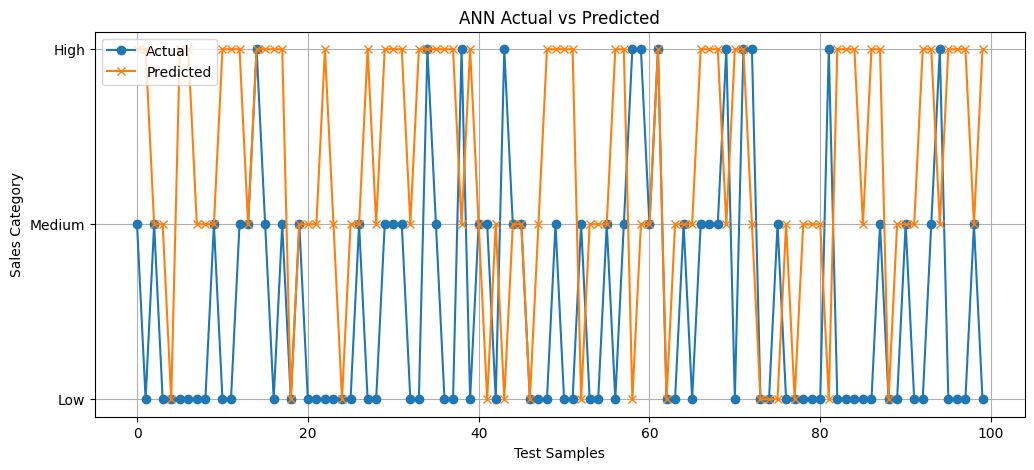

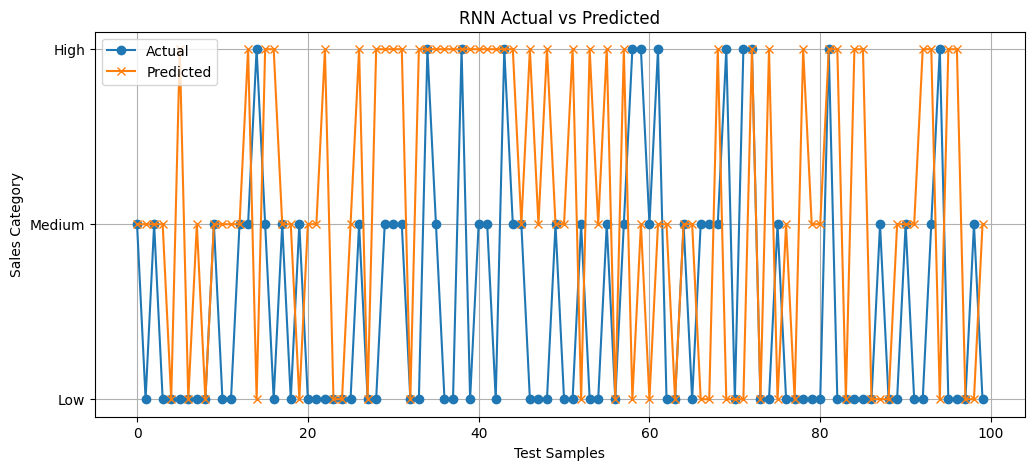

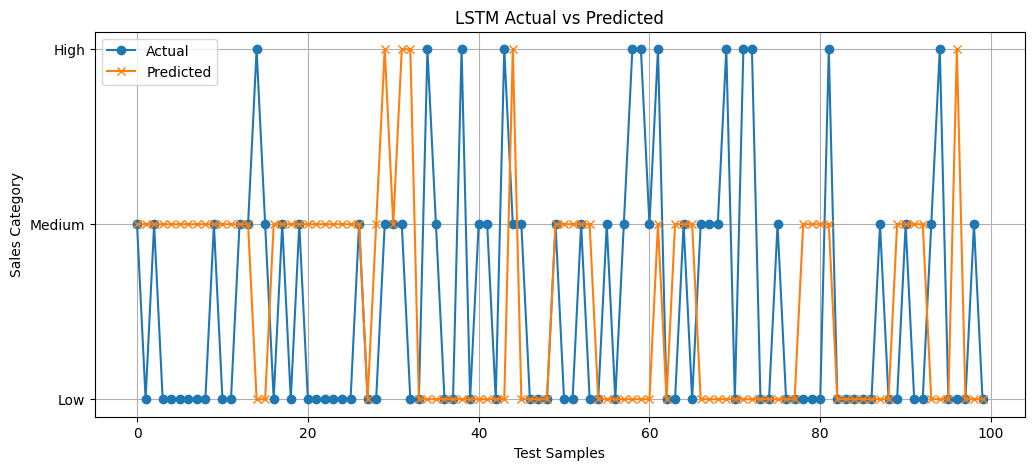

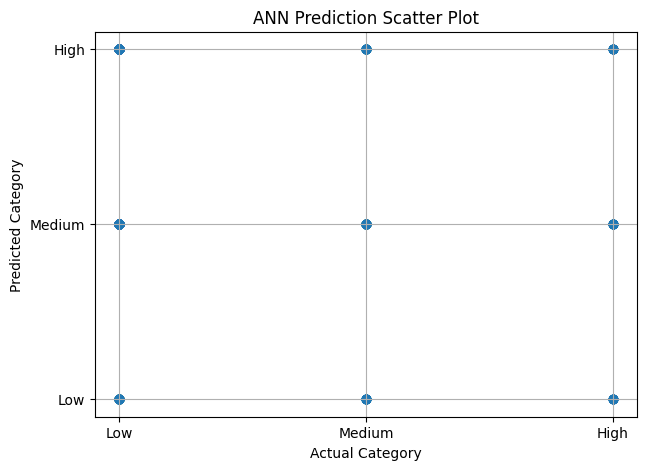

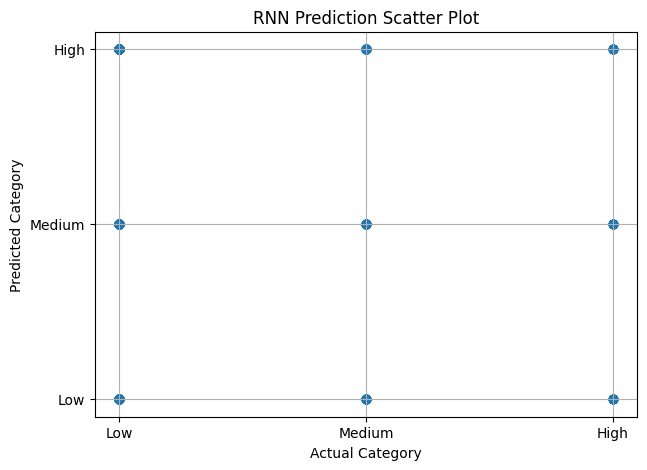

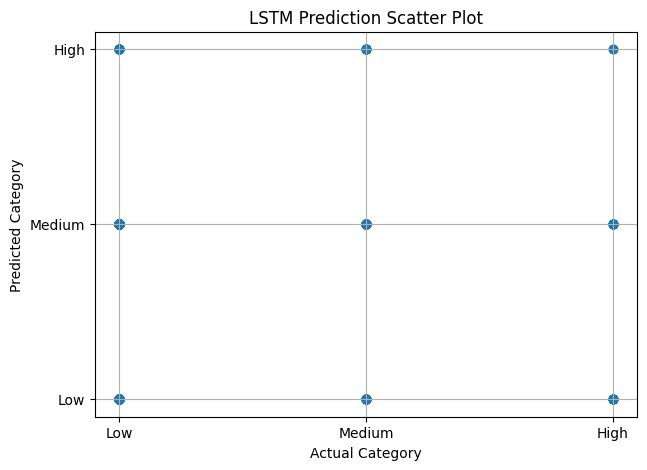

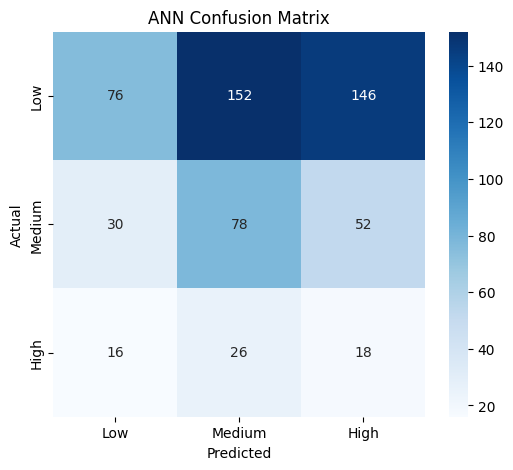

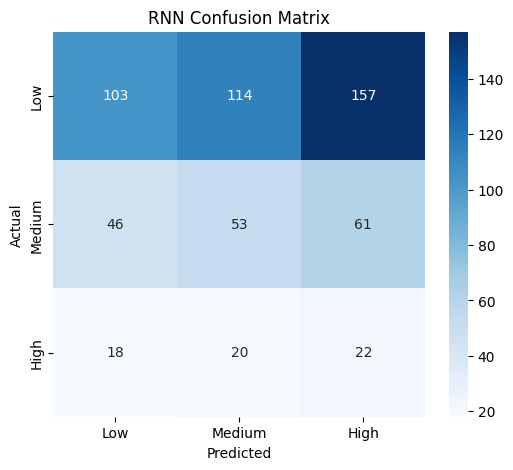

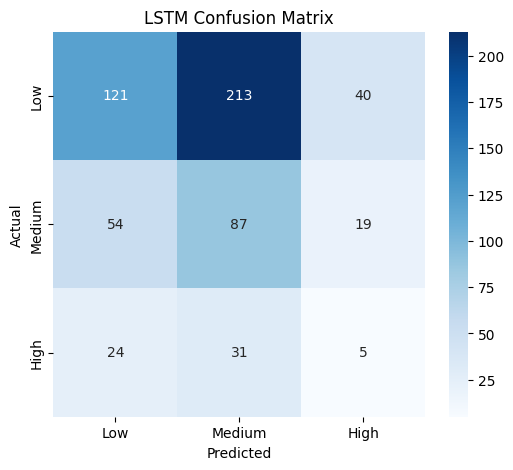


 ANN CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.62      0.20      0.31       374
      Medium       0.30      0.49      0.38       160
        High       0.08      0.30      0.13        60

    accuracy                           0.29       594
   macro avg       0.34      0.33      0.27       594
weighted avg       0.48      0.29      0.31       594


 RNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.62      0.28      0.38       374
      Medium       0.28      0.33      0.31       160
        High       0.09      0.37      0.15        60

    accuracy                           0.30       594
   macro avg       0.33      0.32      0.28       594
weighted avg       0.47      0.30      0.34       594


 LSTM CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.61      0.32      0.42       374
      Medium       0.26      0.54      0.35 

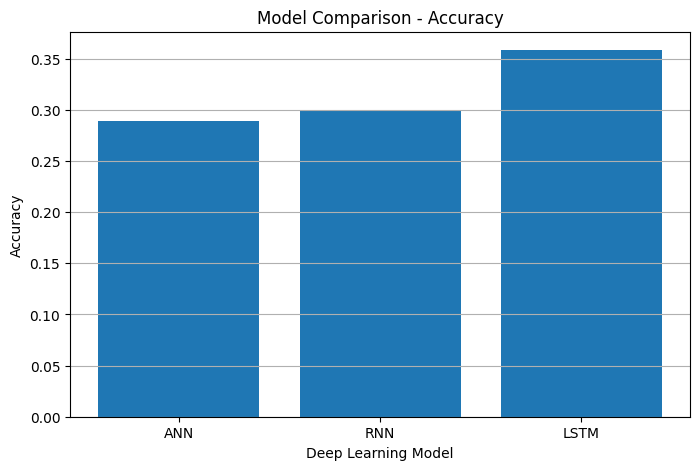

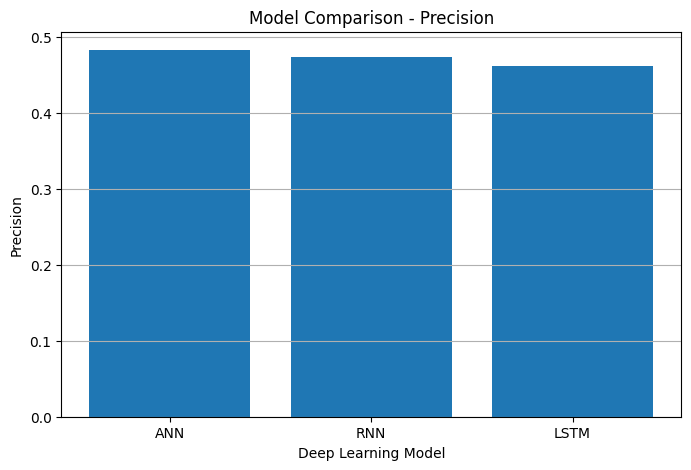

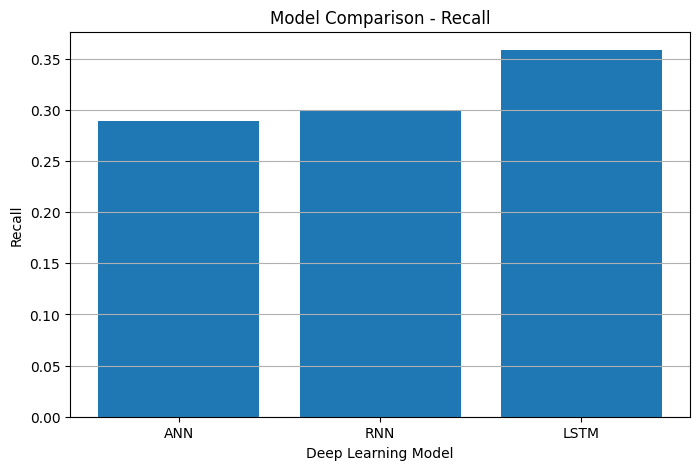

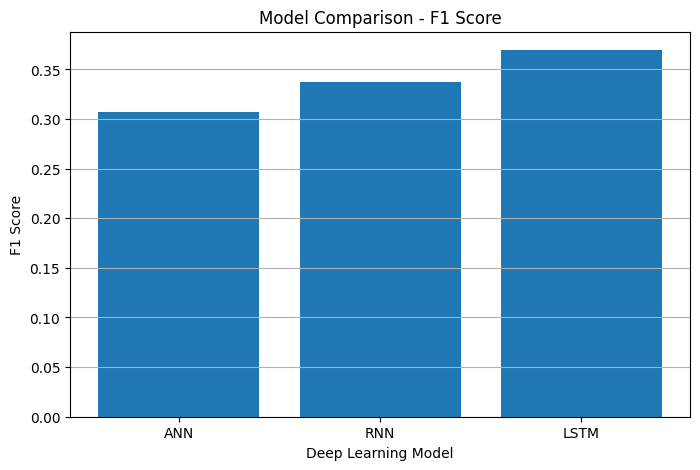

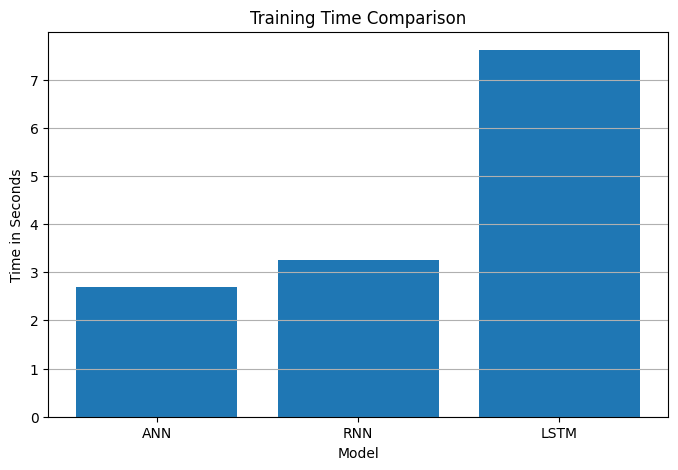


BEST MODEL: LSTM
Accuracy: 0.3586
Precision: 0.4615
Recall: 0.3586
F1 Score: 0.3695

Models Saved Successfully!

SALES CATEGORY PREDICTION COMPLETED

Algorithms Used:
1. ANN
2. RNN
3. LSTM

Problem Type: Multiclass Classification

Categories:
0 - Low
1 - Medium
2 - High

Best Model: LSTM

Final Performance:
Model  Accuracy  Precision  Recall  F1 Score  Training Time
  ANN    0.2896     0.4827  0.2896    0.3071         2.6861
  RNN    0.2997     0.4739  0.2997    0.3368         3.2449
 LSTM    0.3586     0.4615  0.3586    0.3695         7.6114

Saved Files:
ANN_model.pth
RNN_model.pth
LSTM_model.pth
predictions.csv
model_comparison.csv
scaler.pkl
feature_columns.pkl
best_model.pkl

All files saved inside:
Sales_Category_Results/

PROJECT EXECUTION SUCCESSFUL!


In [ ]:
# ============================================================
# PROJECT: SALES CATEGORY PREDICTION USING DEEP LEARNING
# ALGORITHMS: ANN, RNN AND LSTM
# TYPE: MULTICLASS CLASSIFICATION
# ============================================================

# 1. INSTALLATION AND IMPORTS

!pip -q install kagglehub

import os
import glob
import time
import copy
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import kagglehub

warnings.filterwarnings("ignore")

# Random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using Device:", device)


# ============================================================
# 2. AUTOMATIC DATASET DOWNLOAD
# ============================================================

print("\nDownloading Dataset...")

path = kagglehub.dataset_download(
    "rohitsahoo/sales-forecasting"
)

csv_files = glob.glob(
    path + "/**/*.csv",
    recursive=True
)

if not csv_files:
    raise FileNotFoundError("CSV file not found!")

file_path = next(
    (f for f in csv_files
     if os.path.basename(f).lower() == "train.csv"),
    csv_files[0]
)

df = pd.read_csv(file_path)

print("Dataset Downloaded Successfully!")

print("Shape:", df.shape)

print(df.head())


# ============================================================
# 3. DATA CLEANING
# ============================================================

df.columns = df.columns.str.strip()

df.drop_duplicates(inplace=True)

df["Sales"] = pd.to_numeric(
    df["Sales"],
    errors="coerce"
)

df.dropna(subset=["Sales"], inplace=True)

df = df[df["Sales"] >= 0].copy()

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

df.dropna(subset=["Order Date"], inplace=True)

df.sort_values(
    "Order Date",
    inplace=True
)

df.reset_index(drop=True, inplace=True)

print("\nCleaned Dataset:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())


# ============================================================
# 4. CREATE SALES CATEGORIES
# ============================================================

# Low = 0
# Medium = 1
# High = 2

def sales_category(sales):

    if sales < 100:
        return 0

    elif sales < 500:
        return 1

    else:
        return 2


df["Sales_Category"] = df["Sales"].apply(
    sales_category
)

category_names = {
    0: "Low",
    1: "Medium",
    2: "High"
}

df["Category_Name"] = df[
    "Sales_Category"
].map(category_names)

print("\nSales Category Distribution:")

print(
    df["Category_Name"].value_counts()
)


# ============================================================
# 5. EXPLORATORY DATA ANALYSIS
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Category_Name",
    order=["Low", "Medium", "High"]
)

plt.title("Sales Category Distribution")

plt.xlabel("Sales Category")

plt.ylabel("Number of Transactions")

plt.show()


plt.figure(figsize=(8, 5))

sns.histplot(
    df["Sales"],
    bins=40,
    kde=True
)

plt.title("Sales Distribution")

plt.xlabel("Sales Amount")

plt.show()


plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Category",
)

plt.title("Product Category Distribution")

plt.xticks(rotation=30)

plt.show()


# ============================================================
# 6. FEATURE SELECTION
# ============================================================

# Sales from previous transactions is allowed.
# Current transaction Sales is NOT used as input.
# Profit is excluded to avoid target leakage.

numeric_columns = [
    col for col in [
        "Sales",
        "Quantity",
        "Discount"
    ]
    if col in df.columns
]

categorical_columns = [
    col for col in [
        "Category",
        "Sub-Category",
        "Region",
        "Segment",
        "Ship Mode"
    ]
    if col in df.columns
]

features = df[numeric_columns].copy()

for col in categorical_columns:

    encoded = pd.get_dummies(
        df[col].fillna("Unknown"),
        prefix=col,
        dtype=float
    )

    features = pd.concat(
        [features, encoded],
        axis=1
    )

features = features.replace(
    [np.inf, -np.inf],
    np.nan
)

features = features.fillna(0)

print("\nSelected Features:")

print(features.columns.tolist())


# ============================================================
# 7. SEQUENTIAL DATA PREPARATION
# ============================================================

SEQ_LENGTH = 10

X_raw = features.values.astype(np.float32)

y_raw = df["Sales_Category"].values.astype(np.int64)

n = len(df)

train_end = int(n * 0.70)

val_end = int(n * 0.85)

if n <= SEQ_LENGTH + 20:
    raise ValueError("Insufficient dataset records!")

# Fit scaler using training data only.

scaler = StandardScaler()

scaler.fit(
    X_raw[:train_end]
)

X_scaled = scaler.transform(
    X_raw
).astype(np.float32)

X_sequences = []

y_sequences = []

target_indices = []

for i in range(SEQ_LENGTH, n):

    X_sequences.append(
        X_scaled[i-SEQ_LENGTH:i]
    )

    y_sequences.append(
        y_raw[i]
    )

    target_indices.append(i)


X_sequences = np.array(
    X_sequences,
    dtype=np.float32
)

y_sequences = np.array(
    y_sequences,
    dtype=np.int64
)

target_indices = np.array(
    target_indices
)

train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

X_train = X_sequences[train_mask]

y_train = y_sequences[train_mask]

X_val = X_sequences[val_mask]

y_val = y_sequences[val_mask]

X_test = X_sequences[test_mask]

y_test = y_sequences[test_mask]

print("\nDataset Splitting:")

print("Training:", X_train.shape)

print("Validation:", X_val.shape)

print("Testing:", X_test.shape)


# ============================================================
# 8. PYTORCH DATALOADERS
# ============================================================

def create_loader(X, y, shuffle=False):

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y,
        dtype=torch.long
    )

    dataset = TensorDataset(
        X_tensor,
        y_tensor
    )

    return DataLoader(
        dataset,
        batch_size=64,
        shuffle=shuffle
    )


train_loader = create_loader(
    X_train,
    y_train,
    True
)

val_loader = create_loader(
    X_val,
    y_val
)

test_loader = create_loader(
    X_test,
    y_test
)


# ============================================================
# 9. CLASS WEIGHTS
# ============================================================

class_counts = np.bincount(
    y_train,
    minlength=3
)

class_weights = len(y_train) / (
    3 * np.maximum(class_counts, 1)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)


# ============================================================
# 10. ANN MODEL
# ============================================================

class ANN(nn.Module):

    def __init__(self, input_size):

        super().__init__()

        self.network = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                input_size * SEQ_LENGTH,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, 64),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, 3)

        )

    def forward(self, x):

        return self.network(x)


# ============================================================
# 11. RNN MODEL
# ============================================================

class RNNModel(nn.Module):

    def __init__(self, input_size):

        super().__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Linear(64, 3)

    def forward(self, x):

        output, hidden = self.rnn(x)

        return self.fc(
            output[:, -1, :]
        )


# ============================================================
# 12. LSTM MODEL
# ============================================================

class LSTMModel(nn.Module):

    def __init__(self, input_size):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Linear(64, 3)

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        return self.fc(
            output[:, -1, :]
        )


# ============================================================
# 13. TRAINING FUNCTION
# ============================================================

EPOCHS = 100

PATIENCE = 10

LEARNING_RATE = 0.001


def train_model(model, name):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_loss = float("inf")

    best_weights = None

    patience_count = 0

    start_time = time.time()

    print("\nTraining:", name)

    for epoch in range(EPOCHS):

        # Training

        model.train()

        total_loss = 0

        actual = []

        predicted = []

        for xb, yb in train_loader:

            xb = xb.to(device)

            yb = yb.to(device)

            optimizer.zero_grad()

            outputs = model(xb)

            loss = criterion(
                outputs,
                yb
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * len(yb)

            predictions = outputs.argmax(dim=1)

            actual.extend(
                yb.cpu().numpy()
            )

            predicted.extend(
                predictions.detach().cpu().numpy()
            )

        train_loss = (
            total_loss /
            len(train_loader.dataset)
        )

        train_accuracy = accuracy_score(
            actual,
            predicted
        )

        # Validation

        model.eval()

        val_loss_total = 0

        val_actual = []

        val_predicted = []

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(device)

                yb = yb.to(device)

                outputs = model(xb)

                loss = criterion(
                    outputs,
                    yb
                )

                val_loss_total += (
                    loss.item() * len(yb)
                )

                predictions = outputs.argmax(dim=1)

                val_actual.extend(
                    yb.cpu().numpy()
                )

                val_predicted.extend(
                    predictions.cpu().numpy()
                )

        val_loss = (
            val_loss_total /
            len(val_loader.dataset)
        )

        val_accuracy = accuracy_score(
            val_actual,
            val_predicted
        )

        history["train_loss"].append(
            train_loss
        )

        history["val_loss"].append(
            val_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["val_accuracy"].append(
            val_accuracy
        )

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch+1}/{EPOCHS} "
                f"Train Loss: {train_loss:.4f} "
                f"Val Loss: {val_loss:.4f} "
                f"Train Accuracy: {train_accuracy:.4f} "
                f"Val Accuracy: {val_accuracy:.4f}"
            )

        # Early stopping

        if val_loss < best_loss:

            best_loss = val_loss

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            patience_count = 0

        else:

            patience_count += 1

        if patience_count >= PATIENCE:

            print("Early Stopping Triggered!")

            break

    model.load_state_dict(best_weights)

    training_time = time.time() - start_time

    print(
        name,
        "Training Completed:",
        round(training_time, 2),
        "seconds"
    )

    return model, history, training_time


# ============================================================
# 14. TRAIN ALL THREE MODELS
# ============================================================

input_size = X_train.shape[2]

models = {

    "ANN": ANN(input_size),

    "RNN": RNNModel(input_size),

    "LSTM": LSTMModel(input_size)

}

trained_models = {}

histories = {}

training_times = {}

for name, model in models.items():

    trained, history, duration = train_model(
        model,
        name
    )

    trained_models[name] = trained

    histories[name] = history

    training_times[name] = duration


# ============================================================
# 15. TRAINING AND VALIDATION LOSS
# ============================================================

for name in histories:

    plt.figure(figsize=(8, 5))

    plt.plot(
        histories[name]["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        histories[name]["val_loss"],
        label="Validation Loss"
    )

    plt.title(name + " Loss Graph")

    plt.xlabel("Epoch")

    plt.ylabel("Cross Entropy Loss")

    plt.legend()

    plt.grid()

    plt.show()


# ============================================================
# 16. TRAINING AND VALIDATION ACCURACY
# ============================================================

for name in histories:

    plt.figure(figsize=(8, 5))

    plt.plot(
        histories[name]["train_accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        histories[name]["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(name + " Accuracy Graph")

    plt.xlabel("Epoch")

    plt.ylabel("Accuracy")

    plt.legend()

    plt.grid()

    plt.show()


# ============================================================
# 17. PREDICTIONS
# ============================================================

def get_predictions(model, loader):

    model.eval()

    actual = []

    predicted = []

    with torch.no_grad():

        for xb, yb in loader:

            xb = xb.to(device)

            outputs = model(xb)

            predictions = outputs.argmax(dim=1)

            actual.extend(
                yb.numpy()
            )

            predicted.extend(
                predictions.cpu().numpy()
            )

    return np.array(actual), np.array(predicted)


results = {}

for name, model in trained_models.items():

    actual, predicted = get_predictions(
        model,
        test_loader
    )

    results[name] = {
        "actual": actual,
        "predicted": predicted
    }


# ============================================================
# 18. CLASSIFICATION EVALUATION
# ============================================================

performance = []

for name in results:

    actual = results[name]["actual"]

    predicted = results[name]["predicted"]

    accuracy = accuracy_score(
        actual,
        predicted
    )

    precision = precision_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )

    performance.append({

        "Model": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1,

        "Training Time": training_times[name]

    })


performance_df = pd.DataFrame(performance)

print("\n========== CLASSIFICATION RESULTS ==========")

print(
    performance_df.round(4).to_string(index=False)
)


# ============================================================
# 19. ACTUAL VS PREDICTED GRAPHS
# ============================================================

labels = ["Low", "Medium", "High"]

for name in results:

    actual = results[name]["actual"]

    predicted = results[name]["predicted"]

    plt.figure(figsize=(12, 5))

    plt.plot(
        actual[:100],
        label="Actual",
        marker="o"
    )

    plt.plot(
        predicted[:100],
        label="Predicted",
        marker="x"
    )

    plt.title(name + " Actual vs Predicted")

    plt.xlabel("Test Samples")

    plt.ylabel("Sales Category")

    plt.yticks(
        [0, 1, 2],
        labels
    )

    plt.legend()

    plt.grid()

    plt.show()


# ============================================================
# 20. PREDICTION SCATTER PLOTS
# ============================================================

for name in results:

    actual = results[name]["actual"]

    predicted = results[name]["predicted"]

    plt.figure(figsize=(7, 5))

    plt.scatter(
        actual,
        predicted,
        alpha=0.5
    )

    plt.title(name + " Prediction Scatter Plot")

    plt.xlabel("Actual Category")

    plt.ylabel("Predicted Category")

    plt.xticks([0, 1, 2], labels)

    plt.yticks([0, 1, 2], labels)

    plt.grid()

    plt.show()


# ============================================================
# 21. CONFUSION MATRICES
# ============================================================

for name in results:

    actual = results[name]["actual"]

    predicted = results[name]["predicted"]

    cm = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1, 2]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(name + " Confusion Matrix")

    plt.xlabel("Predicted")

    plt.ylabel("Actual")

    plt.show()


# ============================================================
# 22. CLASSIFICATION REPORTS
# ============================================================

for name in results:

    print("\n", name, "CLASSIFICATION REPORT")

    print(
        classification_report(
            results[name]["actual"],
            results[name]["predicted"],
            labels=[0, 1, 2],
            target_names=labels,
            zero_division=0
        )
    )


# ============================================================
# 23. MODEL PERFORMANCE COMPARISON
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    plt.bar(
        performance_df["Model"],
        performance_df[metric]
    )

    plt.title("Model Comparison - " + metric)

    plt.xlabel("Deep Learning Model")

    plt.ylabel(metric)

    plt.grid(axis="y")

    plt.show()


# ============================================================
# 24. TRAINING TIME COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    performance_df["Model"],
    performance_df["Training Time"]
)

plt.title("Training Time Comparison")

plt.xlabel("Model")

plt.ylabel("Time in Seconds")

plt.grid(axis="y")

plt.show()


# ============================================================
# 25. BEST MODEL IDENTIFICATION
# ============================================================

best_row = performance_df.loc[
    performance_df["F1 Score"].idxmax()
]

best_model_name = best_row["Model"]

print("\n====================================")

print("BEST MODEL:", best_model_name)

print("Accuracy:", round(best_row["Accuracy"], 4))

print("Precision:", round(best_row["Precision"], 4))

print("Recall:", round(best_row["Recall"], 4))

print("F1 Score:", round(best_row["F1 Score"], 4))

print("====================================")


# ============================================================
# 26. SAVE TRAINED MODELS
# ============================================================

os.makedirs(
    "Sales_Category_Results",
    exist_ok=True
)

for name, model in trained_models.items():

    torch.save(
        model.state_dict(),
        f"Sales_Category_Results/{name}_model.pth"
    )

print("\nModels Saved Successfully!")


# ============================================================
# 27. SAVE PREDICTION RESULTS
# ============================================================

prediction_df = pd.DataFrame()

prediction_df["Actual"] = results["ANN"]["actual"]

prediction_df["Actual_Category"] = (
    prediction_df["Actual"].map(category_names)
)

for name in results:

    prediction_df[name + "_Prediction"] = (
        results[name]["predicted"]
    )

    prediction_df[name + "_Category"] = (
        prediction_df[name + "_Prediction"].map(
            category_names
        )
    )


prediction_df.to_csv(
    "Sales_Category_Results/predictions.csv",
    index=False
)

performance_df.to_csv(
    "Sales_Category_Results/model_comparison.csv",
    index=False
)

joblib.dump(
    scaler,
    "Sales_Category_Results/scaler.pkl"
)

joblib.dump(
    list(features.columns),
    "Sales_Category_Results/feature_columns.pkl"
)

joblib.dump(
    best_model_name,
    "Sales_Category_Results/best_model.pkl"
)


# ============================================================
# 28. FINAL PROJECT SUMMARY
# ============================================================

print("\n============================================")

print("SALES CATEGORY PREDICTION COMPLETED")

print("============================================")

print("\nAlgorithms Used:")

print("1. ANN")

print("2. RNN")

print("3. LSTM")

print("\nProblem Type: Multiclass Classification")

print("\nCategories:")

print("0 - Low")

print("1 - Medium")

print("2 - High")

print("\nBest Model:", best_model_name)

print("\nFinal Performance:")

print(
    performance_df.round(4).to_string(index=False)
)

print("\nSaved Files:")

print("ANN_model.pth")

print("RNN_model.pth")

print("LSTM_model.pth")

print("predictions.csv")

print("model_comparison.csv")

print("scaler.pkl")

print("feature_columns.pkl")

print("best_model.pkl")

print("\nAll files saved inside:")

print("Sales_Category_Results/")

print("\nPROJECT EXECUTION SUCCESSFUL!")

# ============================================================
# END OF PROJECT
# ============================================================